# 06 - Figure 1: the same scene at 1x, 2x, 3x digital zoom

Depth maps come from the CPU stats kernel (`scripts/scene_stats.py --figure-only`), one
KITTI and one NYUv2 image from the audited subsets. All depth panels of a row share one
colour scale in metres, so a model that respects the zoom keeps the same colours, and a
model that reads apparent size gets "closer" (warmer) as we zoom in.

The number in each panel is the median depth over the pixels that are inside the 3x crop,
i.e. the same physical points in all three columns.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "outputs/figures"
maps = np.load(ROOT / "outputs/results/figure1_maps.npz")
ZOOMS = (1.0, 2.0, 3.0)
MODELS = [("dav2-s", "DA-V2-S"), ("moge2-s", "MoGe-2-S"), ("gt", "GT")]


def centre_box(shape, s_from, s_to=3.0):
    """Pixels of the s_to crop, in an image already zoomed by s_from."""
    h, w = shape
    k = s_to / s_from
    ch, cw = int(round(h / k)), int(round(w / k))
    y0, x0 = (h - ch) // 2, (w - cw) // 2
    return slice(y0, y0 + ch), slice(x0, x0 + cw)


def median_in_core(d, s):
    sl = centre_box(d.shape, s)
    v = d[sl].astype(np.float32)
    v = v[np.isfinite(v) & (v > 0)]
    return float(np.median(v)) if len(v) else np.nan

In [2]:
for ds in ("kitti", "nyu"):
    print(ds)
    for m, label in MODELS:
        meds = [median_in_core(maps[f"{m}|{ds}|{s}"], s) for s in ZOOMS]
        print(f"  {label:28s}", "  ".join(f"{s}x: {v:5.2f} m" for s, v in zip(ZOOMS, meds)))

kitti
  DA-V2-S                      1.0x: 28.50 m  2.0x: 15.14 m  3.0x:  7.84 m


  MoGe-2-S                     1.0x: 22.08 m  2.0x: 16.02 m  3.0x: 11.48 m
  GT                           1.0x: 21.31 m  2.0x: 21.31 m  3.0x: 21.08 m
nyu
  DA-V2-S                      1.0x:  3.85 m  2.0x:  1.66 m  3.0x:  0.52 m
  MoGe-2-S                     1.0x:  2.39 m  2.0x:  2.79 m  3.0x:  2.14 m


  GT                           1.0x:  2.26 m  2.0x:  2.26 m  3.0x:  2.26 m


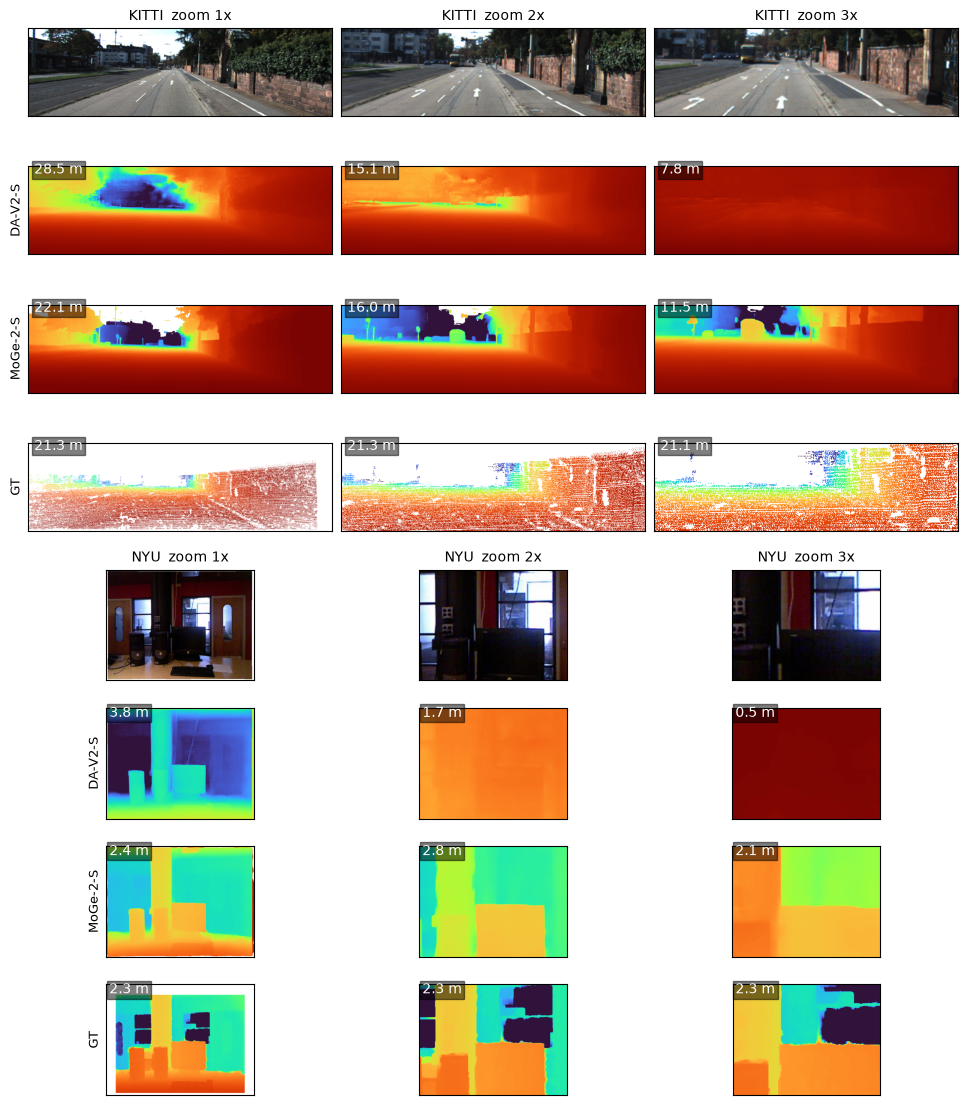

In [3]:
fig, axes = plt.subplots(8, 3, figsize=(12, 14), gridspec_kw={"hspace": 0.25, "wspace": 0.03})
row = 0
for ds in ("kitti", "nyu"):
    vals = np.concatenate([maps[f"{m}|{ds}|{s}"].astype(np.float32).ravel() for m, _ in MODELS[:2] for s in ZOOMS])
    vmin, vmax = np.nanpercentile(vals[vals > 0], [2, 98])
    for k, s in enumerate(ZOOMS):
        ax = axes[row, k]
        ax.imshow(maps[f"img|{ds}|{s}"])
        ax.set_title(f"{ds.upper()}  zoom {s:.0f}x", fontsize=10)
    for j, (m, label) in enumerate(MODELS):
        for k, s in enumerate(ZOOMS):
            ax = axes[row + 1 + j, k]
            d = maps[f"{m}|{ds}|{s}"].astype(np.float32)
            if m == "gt":
                d = np.where(d > 0, d, np.nan)
            im = ax.imshow(d, cmap="turbo_r", vmin=vmin, vmax=vmax)
            ax.text(0.02, 0.92, f"{median_in_core(d, s):.1f} m", transform=ax.transAxes, color="w", fontsize=10,
                    bbox=dict(facecolor="k", alpha=0.5, pad=1.5))
            if k == 0:
                ax.set_ylabel(label, fontsize=9)
    row += 4
for ax in axes.ravel():
    ax.set_xticks([])
    ax.set_yticks([])
plt.savefig(FIG / "06_figure1.png", dpi=120, bbox_inches="tight")
# (the paper versions are made at the end of this notebook)
plt.show()

## Paper versions
The teaser shows only KITTI (wide panels keep it to a third of a page); the NYUv2 example goes
to the supplement with the same layout.

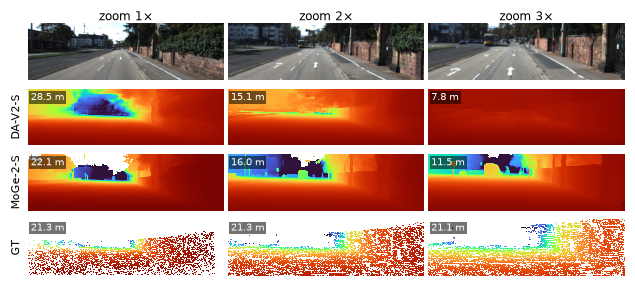

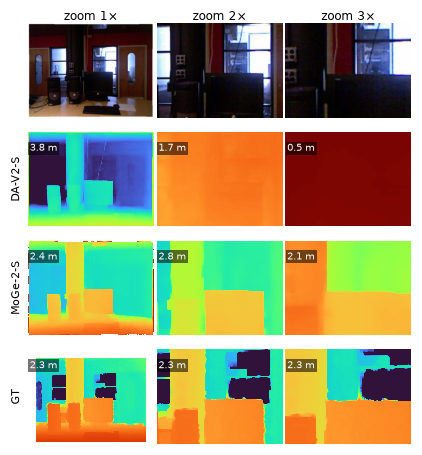

In [4]:
import sys

sys.path.insert(0, str(ROOT / "src"))
import plotstyle as ps

ps.use()


def panel_figure(ds, width):
    h, w = maps[f"img|{ds}|1.0"].shape[:2]
    fig, axes = plt.subplots(4, 3, figsize=(width, width / 3 * h / w * 4 * 1.12), gridspec_kw={"hspace": 0.08, "wspace": 0.02})
    vals = np.concatenate([maps[f"{m}|{ds}|{s}"].astype(np.float32).ravel() for m, _ in MODELS[:2] for s in ZOOMS])
    vmin, vmax = np.nanpercentile(vals[vals > 0], [2, 98])
    for k, s in enumerate(ZOOMS):
        axes[0, k].imshow(maps[f"img|{ds}|{s}"])
        axes[0, k].set_title(f"zoom {s:.0f}×", fontsize=8, pad=2)
        for j, (m, label) in enumerate(MODELS):
            d = maps[f"{m}|{ds}|{s}"].astype(np.float32)
            if m == "gt":
                d = np.where(d > 0, d, np.nan)
            axes[1 + j, k].imshow(d, cmap="turbo_r", vmin=vmin, vmax=vmax, interpolation="nearest")
            axes[1 + j, k].text(0.015, 0.8, f"{median_in_core(d, s):.1f} m", transform=axes[1 + j, k].transAxes,
                                color="w", fontsize=6.5, bbox=dict(facecolor="k", alpha=0.55, pad=1, lw=0))
            if k == 0:
                axes[1 + j, k].set_ylabel(label, fontsize=7)
    for ax in axes.ravel():
        ax.set_xticks([])
        ax.set_yticks([])
        ax.grid(False)
        for sp in ax.spines.values():
            sp.set_visible(False)
    return fig


fig = panel_figure("kitti", 7.0)
fig.savefig(ROOT / "paper/fig/teaser.pdf", bbox_inches="tight")
fig.savefig(FIG / "teaser_kitti.png", bbox_inches="tight")
plt.show()
fig = panel_figure("nyu", 4.5)
ps.save(fig, "figS_teaser_nyu")